In [1]:
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.markers 

plt.rcParams['text.usetex'] = True

In [3]:
# Read the Excel file
df = pd.read_excel('2DIsing_rates.xlsx')

In [4]:
# Grab the entries from the Brendel at al paper
brendel = df[df['source'] == "Brendel et al"]
num_fields = brendel['h'].nunique()
brendel_fields = brendel['h'].unique()

brendel_data = []
brendel_marker = "^"

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']

field_colors = {}

icol = 0

for field in brendel_fields:

    if (field not in field_colors):
        field_colors[field] = colors[icol]
        icol += 1
    
    brendel_beta = brendel[brendel['h']==field]['beta'].to_numpy()
    brendel_rate = brendel[brendel['h']==field]['I (MCSS^1)'].to_numpy()
    brendel_data.append((field, brendel_beta, brendel_rate))

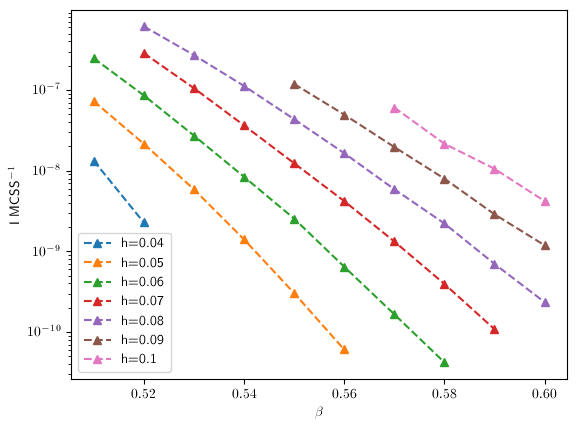

In [5]:
# Plot
for i, data in enumerate(brendel_data):
    plt.plot(data[1], data[2], marker=brendel_marker, label='h='+str(data[0]),linestyle='--',color=field_colors[data[0]])

plt.yscale('log')
plt.xlabel(r"$\beta$")
plt.ylabel(r"I MCSS$^{-1}$")
plt.legend()
plt.show()

In [6]:
# Grab the entries computed with GASP
gasp = df[df['source'] == "GPU_2DIsing"]
num_fields = gasp['h'].nunique()
gasp_fields = gasp['h'].round(2).unique()

gasp_data = []
gasp_marker = "o"

for field in gasp_fields:

    if (field not in field_colors):
        field_colors[field] = colors[icol%10]
        icol += 1
    
    gasp_beta = gasp[gasp['h'].round(2)==field]['beta'].to_numpy()
    gasp_rate = gasp[gasp['h'].round(2)==field]['I (MCSS^1)'].to_numpy()
    gasp_data.append((field, gasp_beta, gasp_rate))

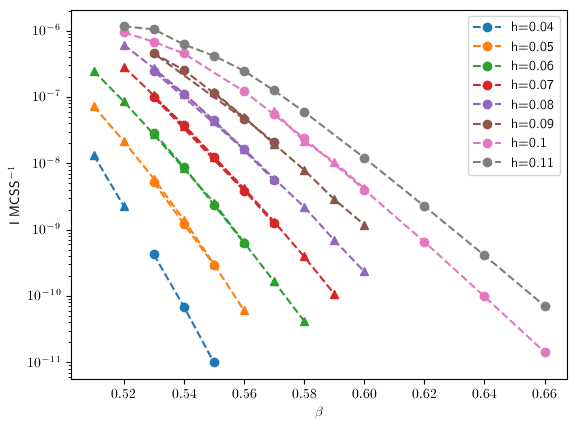

In [7]:
# Plot
for i, data in enumerate(gasp_data):
    plt.plot(data[1], data[2], marker=gasp_marker, label='h='+str(data[0]),linestyle='--',color=field_colors[data[0]])
for i, data in enumerate(brendel_data):
    plt.plot(data[1], data[2], marker=brendel_marker, color=field_colors[data[0]], linestyle='--')

plt.yscale('log')
plt.xlabel(r"$\beta$")
plt.ylabel(r"I MCSS$^{-1}$")
plt.legend()
plt.show()

In [8]:
# Grab the entries computed by Mandal and Quigley with FFS
mandal = df[df['source'] == "Mandal and Quigley (FFS)"]
num_fields = mandal['h'].nunique()
mandal_fields = mandal['h'].round(2).unique()

mandal_data = []
mandal_marker = "*"

for field in mandal_fields:

    if (field not in field_colors):
        field_colors[field] = colors[icol%10]
        icol += 1
    
    mandal_beta = mandal[mandal['h']==field]['beta'].to_numpy()
    mandal_rate = mandal[mandal['h']==field]['I (MCSS^1)'].to_numpy()
    mandal_data.append((field, mandal_beta, mandal_rate))

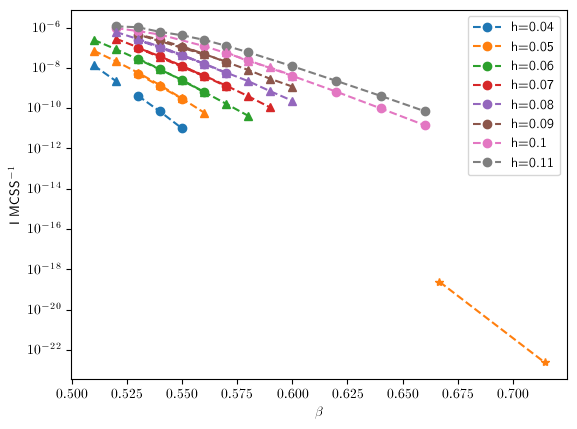

In [9]:
# Plot
for i, data in enumerate(mandal_data):
    plt.plot(data[1], data[2], marker=mandal_marker, color=field_colors[data[0]], linestyle='--')
for i, data in enumerate(gasp_data):
    plt.plot(data[1], data[2], marker=gasp_marker, label='h='+str(data[0]),linestyle='--',color=field_colors[data[0]])
for i, data in enumerate(brendel_data):
    plt.plot(data[1], data[2], marker=brendel_marker, color=field_colors[data[0]], linestyle='--')

plt.yscale('log')
plt.xlabel(r"$\beta$")
plt.ylabel(r"I MCSS$^{-1}$")
plt.legend()
plt.show()

In [10]:
# Grab the entries computed by Ryu and Cai with FFS
ryu = df[df['source'] == "Ryu and Cai"]
num_fields = ryu['h'].nunique()
ryu_fields = ryu['h'].round(3).unique()

ryu_data = []
ryu_marker = 'X'

for field in ryu_fields:

    if (field not in field_colors):
        field_colors[field] = colors[icol%10]
        icol += 1
    
    ryu_beta = ryu[ryu['h'].round(3)==field]['beta'].to_numpy()
    ryu_rate = ryu[ryu['h'].round(3)==field]['I (MCSS^1)'].to_numpy()
    ryu_data.append((field, ryu_beta, ryu_rate))

ryu


,T,beta,h,I (MCSS^1),L,source
139,1.9,0.526316,0.0150,2.342745e-17,100,Ryu and Cai
140,1.9,0.526316,0.0175,2.012084e-15,100,Ryu and Cai
141,1.9,0.526316,0.0225,2.554122e-13,100,Ryu and Cai
142,1.9,0.526316,0.0250,2.614369e-12,100,Ryu and Cai
143,1.9,0.526316,0.0300,2.682412e-11,100,Ryu and Cai
144,1.9,0.526316,0.0350,2.268638e-10,100,Ryu and Cai
145,1.5,0.666667,0.0400,1.012930e-22,100,Ryu and Cai
146,1.5,0.666667,0.0500,2.358028e-19,100,Ryu and Cai
147,1.2,0.833333,0.0500,2.358028e-49,100,Ryu and Cai
148,1.5,0.666667,0.0600,6.533547e-17,100,Ryu and Cai


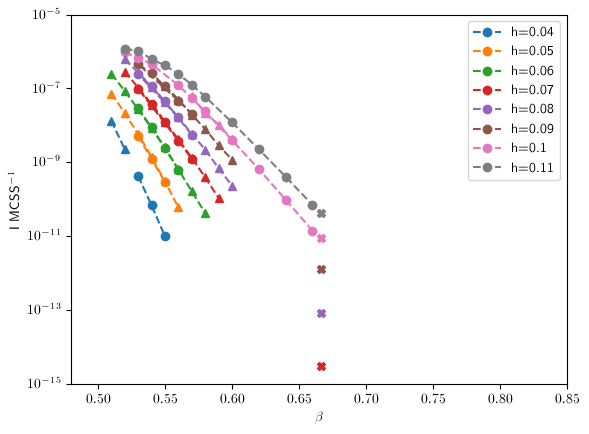

<Figure size 640x480 with 0 Axes>

In [21]:
# Plot

for i, data in enumerate(ryu_data):
    if data[0] >= 0.04 and data[0] <= 0.11:
        plt.plot(data[1], data[2], marker=ryu_marker, color=field_colors[data[0]], linestyle='')
#for i, data in enumerate(mandal_data):
#    plt.plot(data[1], data[2], marker=mandal_marker, color=field_colors[data[0]], linestyle='--')
for i, data in enumerate(gasp_data):
    plt.plot(data[1], data[2], marker=gasp_marker, label='h='+str(data[0]),linestyle='--',color=field_colors[data[0]])
for i, data in enumerate(brendel_data):
    plt.plot(data[1], data[2], marker=brendel_marker, color=field_colors[data[0]], linestyle='--')

plt.yscale('log')
plt.xlabel(r"$\beta$")
plt.ylabel(r"I MCSS$^{-1}$")
plt.xlim((0.48,0.85))
plt.ylim((1e-15,1e-5))
plt.legend()
plt.show()
plt.savefig('rates.pdf')

Help on function imsave in module matplotlib.pyplot:

imsave(fname: 'str | os.PathLike | BinaryIO', arr: 'ArrayLike', **kwargs) -> 'None'
    Colormap and save an array as an image file.

    RGB(A) images are passed through.  Single channel images will be
    colormapped according to *cmap* and *norm*.

    .. note::

       If you want to save a single channel image as gray scale please use an
       image I/O library (such as pillow, tifffile, or imageio) directly.

    Parameters
    ----------
    fname : str or path-like or file-like
        A path or a file-like object to store the image in.
        If *format* is not set, then the output format is inferred from the
        extension of *fname*, if any, and from :rc:`savefig.format` otherwise.
        If *format* is set, it determines the output format.
    arr : array-like
        The image data. Accepts NumPy arrays or sequences
        (e.g., lists or tuples). The shape can be one of
        MxN (luminance), MxNx3 (RGB) or Mx